# Curves for many groups

A curve per store, nested in regions. Small stores have too little data for a curve of their own, so
`drcurves` pools them: each store's curve is the overall curve plus a regional deviation plus a store
deviation, and small stores are shrunk toward their region.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from drcurves import fit_dose_response
from drcurves.simulate import sim_hierarchical

df, truth, _ = sim_hierarchical(seed=0)
df.groupby("store").size().describe()[["min", "50%", "max"]]

min      8.0
50%     56.0
max    733.0
dtype: float64

In [2]:
model = fit_dose_response(df[["x0", "x1", "x2"]], df["A"], df["Y"],
                          groups=df[["region", "store"]])
d = model.diagnostics()
d["groups"], d["weights"]["ess_share"]

/tmp/ipykernel_11850/452630212.py:1: UserWarning: 3 of 200 groups have fewer than 10 rows; their curves will lean almost entirely on their parent group.
  model = fit_dose_response(df[["x0", "x1", "x2"]], df["A"], df["Y"],


({'n_groups': 200, 'min_rows': 8, 'groups_with_constant_dose': []},
 0.5081762909669133)

## A small store and a big one

The small store's curve leans on its region; the big store's data can overrule the shrinkage.

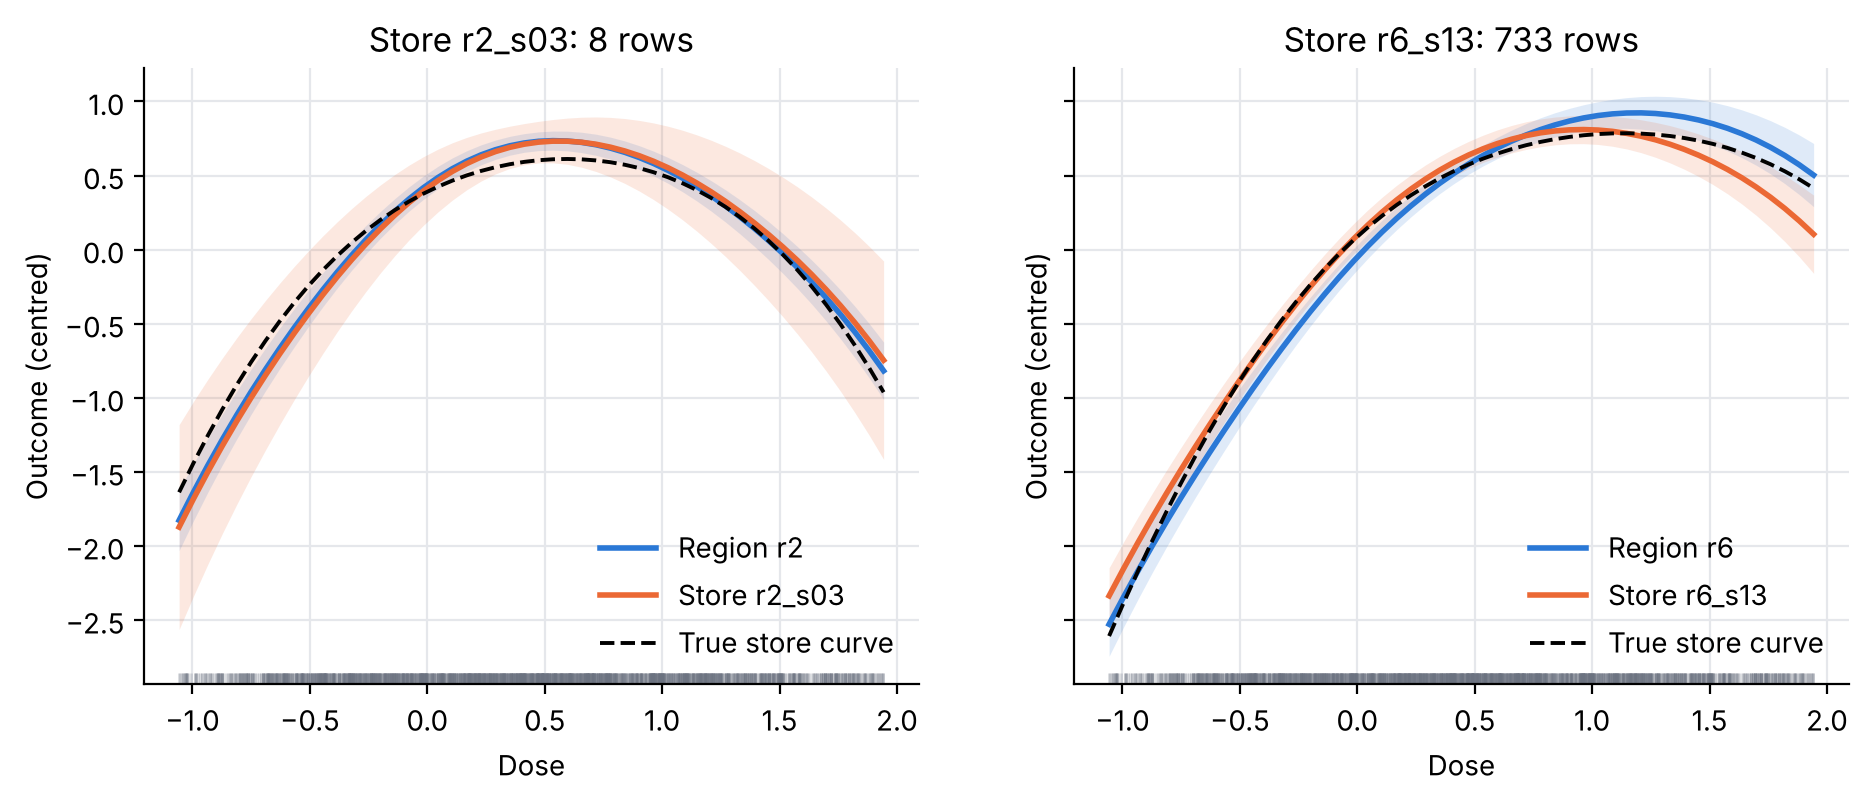

In [3]:
sizes = df.groupby("store").size()
small, big = sizes.idxmin(), sizes.idxmax()
region = lambda s: df.loc[df.store == s, "region"].iloc[0]
grid = np.linspace(*np.quantile(df["A"], [0.05, 0.95]), 50)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, s in zip(axes, [small, big]):
    r = region(s)
    model.plot(grid, paths=[(r,), (r, s)], labels=[f"Region {r}", f"Store {s}"], centre=True, ax=ax)
    t = truth[(r, s)](grid); ax.plot(grid, t - t.mean(), "k--", lw=1.4, label="True store curve")
    ax.set_title(f"Store {s}: {sizes[s]} rows"); ax.legend(frameon=False)

## A store with no data

An unseen store gets its region's curve. Its band is the region's band: it does not yet add the spread
between stores, so treat it as a lower bound on the uncertainty for a brand-new store.

In [4]:
r = region(small)
est_new, se_new = model.curve(grid, (r, "brand_new_store"))
est_reg, se_reg = model.curve(grid, (r,))
np.allclose(est_new, est_reg)

True

## Comparing groups

`contrast` compares two doses for one group, or two groups at the same dose.

In [5]:
a0, a1 = np.quantile(df["A"], [0.25, 0.75])
for s in [small, big]:
    lift, se = model.contrast(a0, a1, (region(s), s))
    print(f"Store {s}: moving the dose from {a0:.2f} to {a1:.2f} changes the outcome by {lift:.2f} (s.e. {se:.2f})")

Store r2_s03: moving the dose from -0.19 to 1.04 changes the outcome by 0.38 (s.e. 0.29)
Store r6_s13: moving the dose from -0.19 to 1.04 changes the outcome by 1.03 (s.e. 0.10)
